<h1 style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-weight: 700; margin-bottom: 20px;">
Financial Distress Early Warning and Explainable ML System
</h1>

<p style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-size: 15px; line-height: 1.6;">
<b>Author:</b> Eegunjobi Feranmi<br>
<b>Dataset:</b> Financial ratios and recorded bankruptcy outcomes for Polish companies<br>
<b>Stack:</b> Python, Pandas, Scikit-learn, SHAP <br>
<b>Models:</b> Elastic Net Logistic Regression, LightGBM
</p>

<hr style="border: 0.5px solid #d1d1d1;">

<h2 style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-weight: 600;">
Business Problem
</h2>

<p style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-size: 15px; line-height: 1.6;">
Corporate insolvencies are still rising worldwide. According to Allianz Trade's Global Insolvency Outlook (April 2026), global business insolvencies will rise by 6% in 2026, marking a fifth consecutive year of increases and pushing failures to a record high, 24% above pre-pandemic levels. This will put 2.2 million jobs directly at risk in 2026 alone. For banks, credit insurers and advisory firms, a single corporate failure can mean unrecoverable loans, unpaid claims or investment losses, yet analysts cannot manually review the financial statements of every borrower or investment target. They need an automated early warning system that screens companies at scale and shows why each one is flagged.
</p>

<p style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-size: 15px; line-height: 1.6;">
This project builds a machine learning model that predicts bankruptcy risk from historical financial ratios, comparing an Elastic Net Logistic Regression baseline with a gradient boosted model LightGBM and using SHAP to explain which ratios drive each company risk score. Because bankruptcies are rare, the models are judged on recall, precision and PR AUC rather than accuracy, and the decision threshold is tuned to balance missed bankruptcies against false alarms. The predicted probabilities are then converted into a risk ranked list so analysts can investigate the highest risk companies first. The prototype tests the approach on a public historical benchmark, and it does not prove why companies fail or that the model will work for present day Nigerian firms.
</p>

<p style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-size: 15px; line-height: 1.6;">
<b>Business Question:</b> Can we predict whether a company is at risk of bankruptcy from its historical financial ratios, explain why it was flagged, and help analysts prioritise which companies to investigate first?
</p>

<hr style="border: 0.5px solid #d1d1d1;">

<h2 style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-weight: 600;">
Dataset
</h2>

<p style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-size: 15px; line-height: 1.6;">
This project uses the Polish Companies Bankruptcy dataset from the UCI Machine Learning Repository, which provides five separate forecasting datasets. Only the first year file is used here, so all results apply to that file and not to the full collection. It contains 7,027 company observations, of which 271 (3.9 percent) went bankrupt during the specified forecast period and 6,756 (96.1 percent) did not, a ratio of roughly 25 healthy companies for every bankrupt one. The data consists of financial ratios drawn from historical company records, principally covering 2000 to 2013.
</p>

<hr style="border: 0.5px solid #d1d1d1;">

<h2 style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-weight: 600;">
Step 1 — Import Libraries
</h2>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy.io import arff
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

<hr style="border: 0.5px solid #d1d1d1;">

<h2 style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-weight: 600; text-align: left;">
Step 2 — Load the Data
</h2>

In [2]:
file_path = data/raw/polish_bankruptcy_1year.arff

data, meta = arff.loadarff(file_path)
df = pd.DataFrame(data)

# Decode byte strings to normal strings (ARFF loads as bytes)
for col in df.select_dtypes([object]).columns:
    df[col] = df[col].apply(lambda x: x.decode('utf-8') if isinstance(x, bytes) else x)

# Quick check
df.head()

,Attr1,Attr2,Attr3,Attr4,Attr5,Attr6,Attr7,Attr8,Attr9,Attr10,...,Attr56,Attr57,Attr58,Attr59,Attr60,Attr61,Attr62,Attr63,Attr64,class
0,0.200550,0.37951,0.39641,2.0472,32.3510,0.38825,0.249760,1.33050,1.1389,0.50494,...,0.121960,0.39718,0.87804,0.001924,8.4160,5.1372,82.658,4.4158,7.4277,0
1,0.209120,0.49988,0.47225,1.9447,14.7860,0.00000,0.258340,0.99601,1.6996,0.49788,...,0.121300,0.42002,0.85300,0.000000,4.1486,3.2732,107.350,3.4000,60.9870,0
2,0.248660,0.69592,0.26713,1.5548,-1.1523,0.00000,0.309060,0.43695,1.3090,0.30408,...,0.241140,0.81774,0.76599,0.694840,4.9909,3.9510,134.270,2.7185,5.2078,0
3,0.081483,0.30734,0.45879,2.4928,51.9520,0.14988,0.092704,1.86610,1.0571,0.57353,...,0.054015,0.14207,0.94598,0.000000,4.5746,3.6147,86.435,4.2228,5.5497,0
4,0.187320,0.61323,0.22960,1.4063,-7.3128,0.18732,0.187320,0.63070,1.1559,0.38677,...,0.134850,0.48431,0.86515,0.124440,6.3985,4.3158,127.210,2.8692,7.8980,0


<hr style="border: 0.5px solid #d1d1d1;">

<h2 style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-weight: 600; text-align: left;">
Step 3 — Data Understanding
</h2>

<p style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Helvetica, Arial, sans-serif; font-size: 15px;">
Before any analysis, I want to understand the structure of the data. This includes checking data types, missing values, duplicates, and basic statistics. This is the first thing a data scientist does when working with a new dataset.
</p>

In [3]:
df.shape

(7027, 65)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7027 entries, 0 to 7026
Data columns (total 65 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Attr1   7024 non-null   float64
 1   Attr2   7024 non-null   float64
 2   Attr3   7024 non-null   float64
 3   Attr4   6997 non-null   float64
 4   Attr5   7019 non-null   float64
 5   Attr6   7024 non-null   float64
 6   Attr7   7024 non-null   float64
 7   Attr8   7002 non-null   float64
 8   Attr9   7026 non-null   float64
 9   Attr10  7024 non-null   float64
 10  Attr11  6988 non-null   float64
 11  Attr12  6997 non-null   float64
 12  Attr13  7027 non-null   float64
 13  Attr14  7024 non-null   float64
 14  Attr15  7025 non-null   float64
 15  Attr16  7002 non-null   float64
 16  Attr17  7002 non-null   float64
 17  Attr18  7024 non-null   float64
 18  Attr19  7027 non-null   float64
 19  Attr20  7027 non-null   float64
 20  Attr21  5405 non-null   float64
 21  Attr22  7024 non-null   float64
 22  

In [5]:
pd.set_option('display.max_columns', None)

df.describe()

,Attr1,Attr2,Attr3,Attr4,Attr5,Attr6,Attr7,Attr8,Attr9,Attr10,Attr11,Attr12,Attr13,Attr14,Attr15,Attr16,Attr17,Attr18,Attr19,Attr20,Attr21,Attr22,Attr23,Attr24,Attr25,Attr26,Attr27,Attr28,Attr29,Attr30,Attr31,Attr32,Attr33,Attr34,Attr35,Attr36,Attr37,Attr38,Attr39,Attr40,Attr41,Attr42,Attr43,Attr44,Attr45,Attr46,Attr47,Attr48,Attr49,Attr50,Attr51,Attr52,Attr53,Attr54,Attr55,Attr56,Attr57,Attr58,Attr59,Attr60,Attr61,Attr62,Attr63,Attr64
count,7024.000000,7024.000000,7024.000000,6997.000000,7.019000e+03,7024.000000,7024.000000,7002.000000,7026.000000,7024.000000,6988.000000,6997.000000,7027.000000,7024.000000,7.025000e+03,7002.000000,7002.000000,7024.000000,7027.000000,7.027000e+03,5405.000000,7024.000000,7027.000000,6903.000000,7024.000000,7002.000000,6.716000e+03,6993.000000,7024.000000,7027.000000,7027.000000,6989.000000,6997.000000,7002.000000,7024.000000,7024.000000,4287.000000,7024.000000,7027.000000,6997.000000,6943.000000,7027.000000,7.027000e+03,7.027000e+03,6893.000000,6996.000000,6998.000000,7024.000000,7027.000000,7002.000000,7024.000000,6998.000000,6993.000000,6993.000000,7.027000e+03,7.027000e+03,7026.000000,7.027000e+03,7026.000000,6.892000e+03,7005.000000,7.027000e+03,6997.000000,6993.000000
mean,0.034660,0.560215,0.119969,2.629143,-2.631672e+02,0.059712,0.313876,2.623996,5.552855,1.825832,0.354393,0.799824,2.093345,0.313876,1.802696e+03,0.870690,3.751868,0.313876,0.462392,1.162128e+03,10.367516,0.288163,0.423610,0.540231,1.264430,0.831449,1.321989e+03,2.702905,4.194831,23.568949,0.473717,236.571445,7.144093,3.666283,0.306880,5.900730,173.453694,1.911897,0.269342,0.826132,0.604475,0.263638,4.588504e+03,3.426404e+03,-30.208158,1.853339,86.752262,0.148865,-1.367363,2.039821,0.467683,0.584584,98.720579,99.636002,8.855693e+03,-1.577367e+02,0.193243,1.587409e+02,0.277829,4.328830e+02,15.642228,4.763202e+03,8.126852,208.731950
std,4.565504,5.350084,5.275459,13.257356,3.707460e+04,6.051113,8.353274,18.708327,101.995448,33.836452,8.658758,5.316444,159.699448,8.353274,8.392232e+04,5.595342,19.514235,8.353274,30.646874,9.315822e+04,417.358298,8.337193,29.742101,13.501067,28.976962,7.781771,3.550416e+04,27.434030,0.677757,1826.847970,30.647711,4841.844793,17.077782,16.338097,7.565155,101.995601,6339.491580,33.835785,27.064231,12.594535,13.834767,27.071123,3.627309e+05,2.696211e+05,3088.908964,12.882415,1131.891001,7.793534,107.717867,5.039658,5.278947,8.527220,2785.367407,2799.586619,7.247527e+04,1.322125e+04,4.344046,1.322124e+04,6.339149,2.612802e+04,261.554534,3.107835e+05,19.996419,5140.708804
min,-256.890000,-72.162000,-440.500000,0.000000,-2.722100e+06,-397.890000,-189.560000,-141.410000,0.000005,-440.550000,-189.450000,-23.207000,-607.420000,-189.560000,-5.611900e+06,-42.322000,-0.412920,-189.560000,-622.060000,0.000000e+00,-1325.000000,-216.800000,-634.590000,-189.560000,-459.560000,-21.793000,-1.479000e+04,-490.090000,0.176090,-149.070000,-622.060000,0.000000,0.000000,-280.260000,-169.470000,0.000005,-525.520000,-440.550000,-701.630000,-101.270000,-77.791000,-701.630000,0.000000e+00,0.000000e+00,-256230.000000,-101.260000,0.000000,-218.420000,-9001.000000,0.000000,0.000000,0.000000,-130.470000,-122.030000,-8.004700e+05,-1.108300e+06,-315.370000,-4.194000e-03,-327.970000,4.700000e-05,0.000016,0.000000e+00,0.000015,0.000010
25%,0.021182,0.296678,0.026968,1.063100,-4.449800e+01,0.000000,0.028023,0.445710,1.037225,0.300785,0.038218,0.063057,0.038073,0.028023,3.435400e+02,0.122810,1.467025,0.028023,0.014812,1.708300e+01,1.024400,0.020362,0.011253,0.049077,0.195252,0.110262,2.353975e-01,0.050522,3.720875,0.094681,0.019233,48.291000,3.050500,0.247445,0.023120,1.264700,1.296500,0.419380,0.012786,0.052276,0.034762,0.011540,6.525600e+01,3.387300e+01,0.102010,0.610012,18.293000,-0.016980,-0.009992,0.805425,0.216135,0.132110,0.715110,0.972140,9.712000e+01,2.031450e-02,0.056772,8.647650e-01,0.000000,5.923950e+00,4.829000,4.322250e+01,3.425400,2.538600
50%,0.075802,0.482960,0.181275,1.502000,-5.373900e+00,0.000000,0.090109,1.015

In [6]:
(df.isnull().mean() * 100).loc[lambda x: x > 0].sort_values(ascending=False).round(2).to_frame(name='Percentage of Missing Values')

,Percentage of Missing Values
Attr37,38.99
Attr21,23.08
Attr27,4.43
Attr60,1.92
Attr45,1.91
Attr24,1.76
Attr41,1.20
Attr11,0.56
Attr32,0.54
Attr28,0.48


In [7]:
df.duplicated().sum()

np.int64(82)

In [8]:
c = df.iloc[:, -1].astype(str).str.extract(r'(\d)').astype(int).iloc[:,0]

pd.DataFrame({
    'Status': ['Bankrupt', 'Not Bankrupt'],
    'Number of Companies': [(c == 1).sum(), (c == 0).sum()]
})

,Status,Number of Companies
0,Bankrupt,271
1,Not Bankrupt,6756


---
### Step 4 — Exploratory Data Analysis
The goal is to find patterns in the dataset.

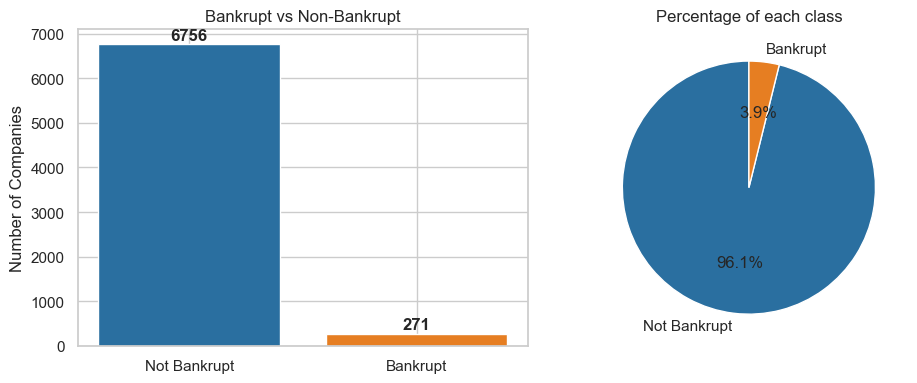

In [9]:
# How rare is bankruptcy in the dataset?

y = df.iloc[:, -1].astype(str).str.extract(r'(\d)').astype(int).iloc[:,0]
counts = y.value_counts().sort_index() # 0 = Not Bankrupt, 1 = Bankrupt
labels = ['Not Bankrupt', 'Bankrupt']

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# 1. Bar chart
ax[0].bar(labels, counts.values, color=['#2a6fa0', '#e67e22'])
ax[0].set_title('Bankrupt vs Non-Bankrupt')
ax[0].set_ylabel('Number of Companies')
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 100, str(v), ha='center', fontweight='bold')

# 2. Pie chart
ax[1].pie(counts.values, labels=labels, autopct='%1.1f%%', colors=['#2a6fa0', '#e67e22'], startangle=90)
ax[1].set_title('Percentage of each class')

plt.tight_layout()
plt.show()

Bankruptcy cases make up only 3.9% of all companies (271 out of 7,027). This extreme imbalance means the model needs special handling, so we will use class_weight to make the model pay more attention to bankrupt cases.

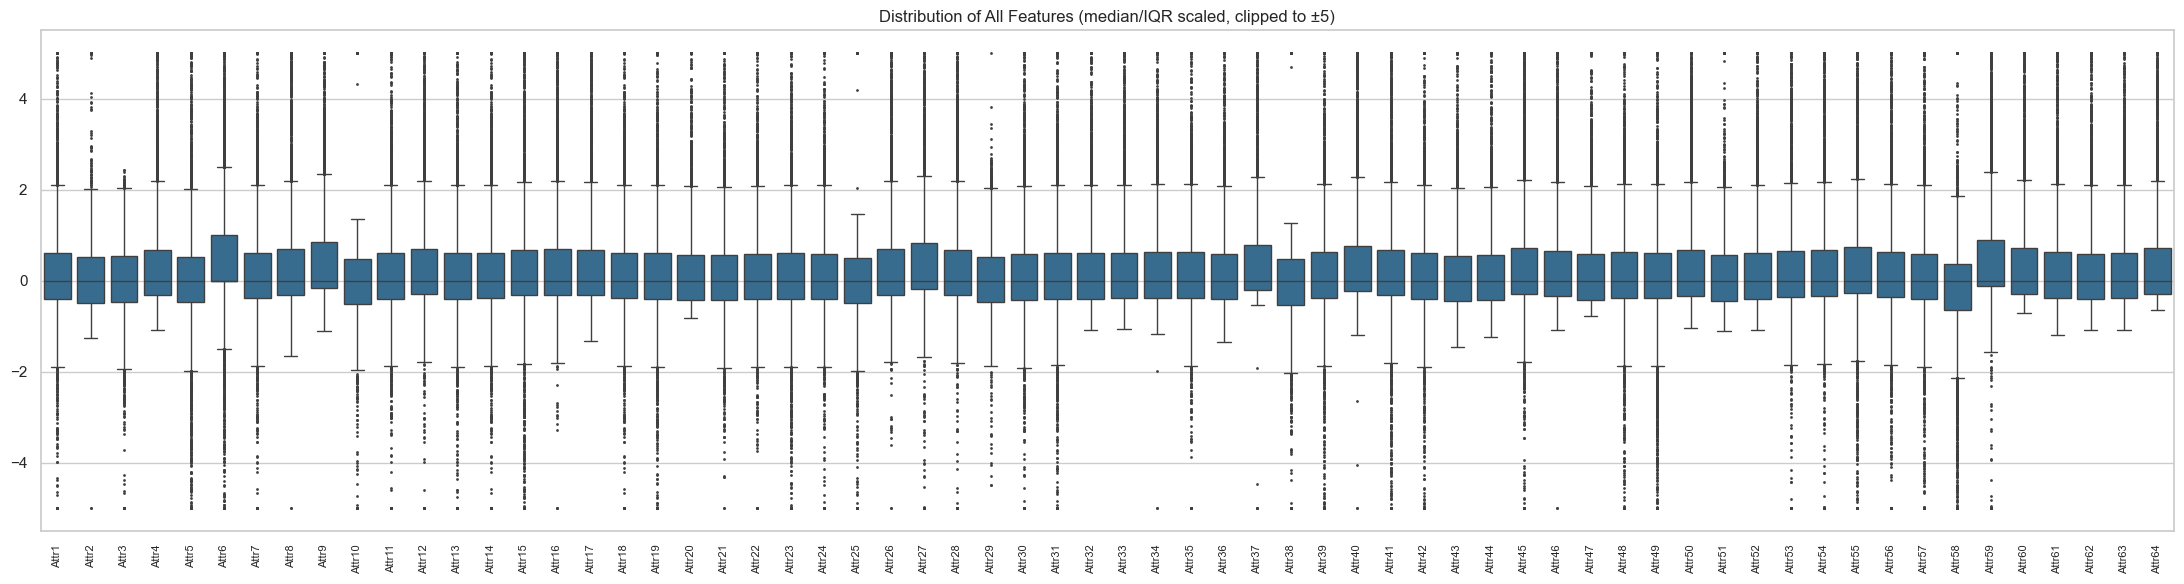

In [10]:
# How are the financial ratios distributed?

features = [f'Attr{i}' for i in range(1, 65)]
scaled = (df[features] - df[features].median()) / (df[features].quantile(0.75) - df[features].quantile(0.25))
scaled = scaled.clip(-5, 5)

plt.figure(figsize=(22, 6))
sns.boxplot(data=scaled, color='#2a6f9d', fliersize=1)
plt.xticks(rotation=90, fontsize=8)
plt.title('Distribution of All Features (median/IQR scaled, clipped to ±5)')
plt.tight_layout()
plt.show()

After median/IQR scaling, the core of most features (the central 50% of values) sits tightly around zero, but nearly all of them show long tails of extreme outliers reaching the ±5 clipping limit on both sides. This indicates that the financial ratios are heavily skewed and outlier-prone, and the true extremes are larger than displayed since values were clipped. Only a few features have noticeably shorter tails.

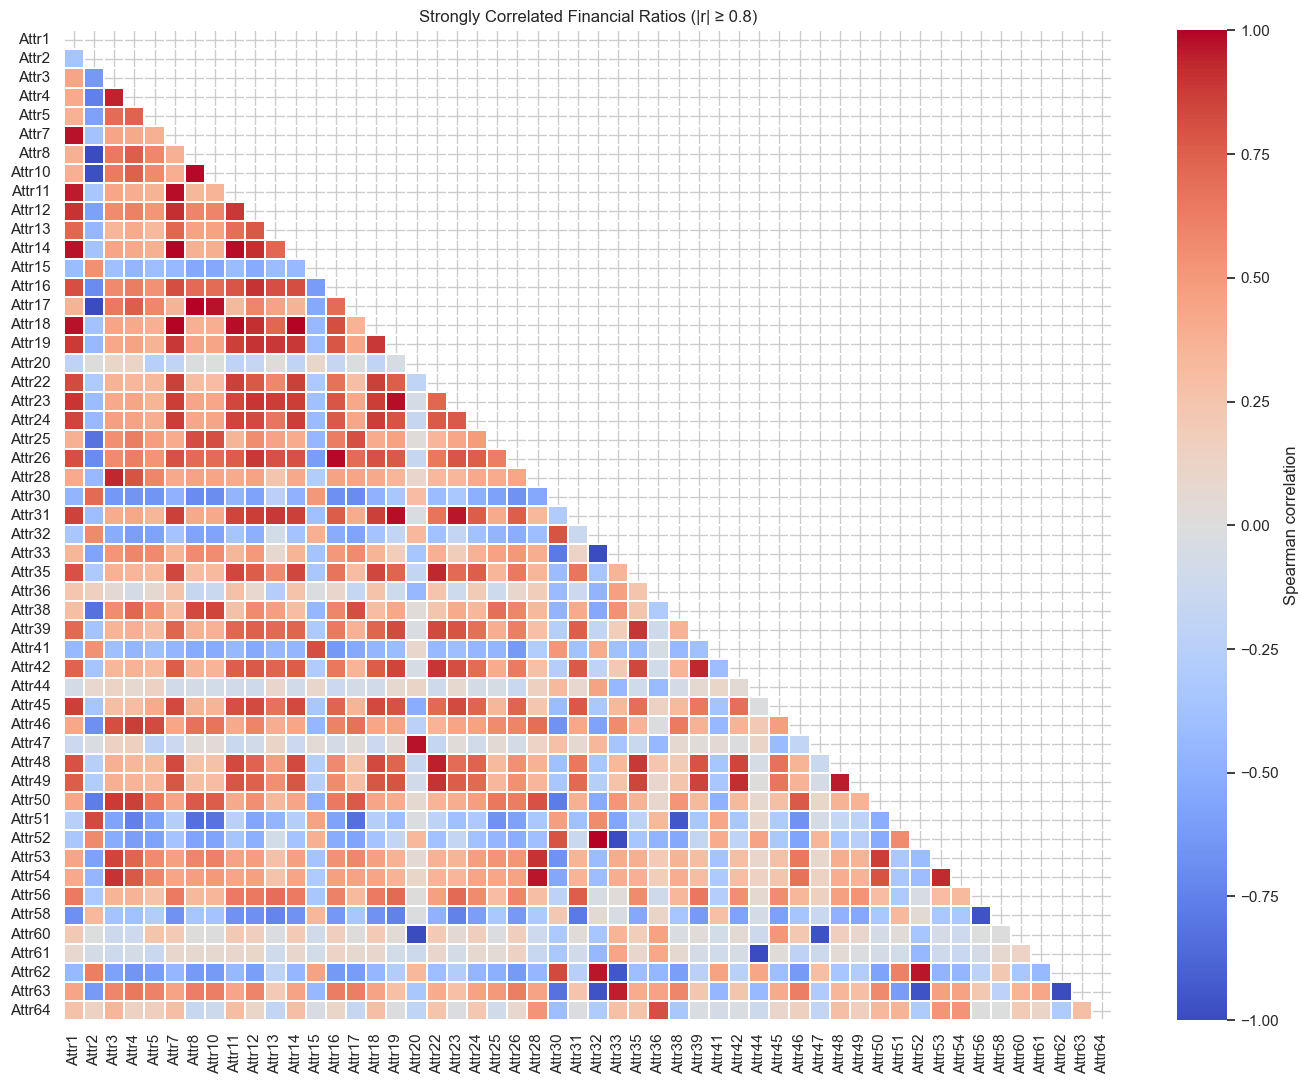

In [11]:
# Which financial ratios are strongly correlated with one another?

corr = df[features].corr(method='spearman')
strong = (corr.abs() >= 0.8) & (corr.abs() < 1)
involved = corr.columns[strong.any()]
sub = corr.loc[involved, involved]

plt.figure(figsize=(14, 11))
sns.heatmap(sub, mask=np.triu(np.ones_like(sub, dtype=bool)), cmap='coolwarm',
            center=0, vmin=-1, vmax=1, linewidths=0.3, cbar_kws={'label': 'Spearman correlation'})
plt.title('Strongly Correlated Financial Ratios (|r| ≥ 0.8)')
plt.tight_layout()
plt.show()

Many ratios are highly correlated, so the baseline will use Elastic Net Logistic Regression, whose L2 penalty lets correlated ratios share weight and whose L1 penalty removes redundant ones. Gradient boosting is not strongly affected by correlated features, so its predictive performance is expected to hold. Because SHAP spreads credit across related ratios, the explanations will be read as the contribution of groups of related ratios rather than any single one. Any correlation-based selection will be computed on the training set only to avoid leaking test information.

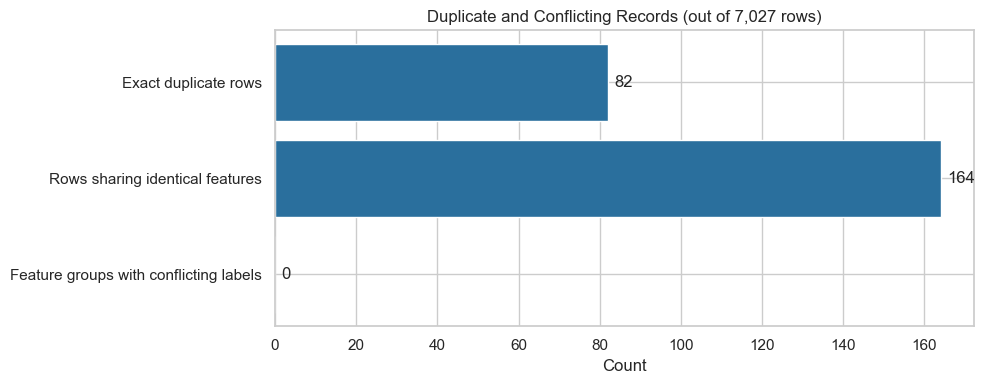

In [12]:
# Are there duplicate records or conflicting observations?

exact_dups = df.duplicated().sum()
same_features = df.duplicated(subset=features, keep=False).sum()
conflicting_groups = (df[df.duplicated(subset=features, keep=False)]
                      .groupby(features, dropna=False)['class'].nunique().gt(1).sum())

labels = ['Exact duplicate rows', 'Rows sharing identical features', 'Feature groups with conflicting labels']
values = [exact_dups, same_features, conflicting_groups]

plt.figure(figsize=(10, 4))
bars = plt.barh(labels, values, color=['#2a6f9d', '#2a6f9d', '#e67e22'])
for bar, v in zip(bars, values):
    plt.text(v + max(values + [1]) * 0.01, bar.get_y() + bar.get_height() / 2, f'{v:,}', va='center')
plt.title(f'Duplicate and Conflicting Records (out of {len(df):,} rows)')
plt.xlabel('Count')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

The data contains 82 exact duplicate rows (about 1.2% of the 7,027 records), and 164 rows share identical feature values, which is consistent with the duplicates being repeated copies of 82 original records. No group of identical feature values carries conflicting bankruptcy labels, so the duplicates do not introduce label noise. This means the duplication is a data quality issue to be aware of rather than a source of contradictory information.

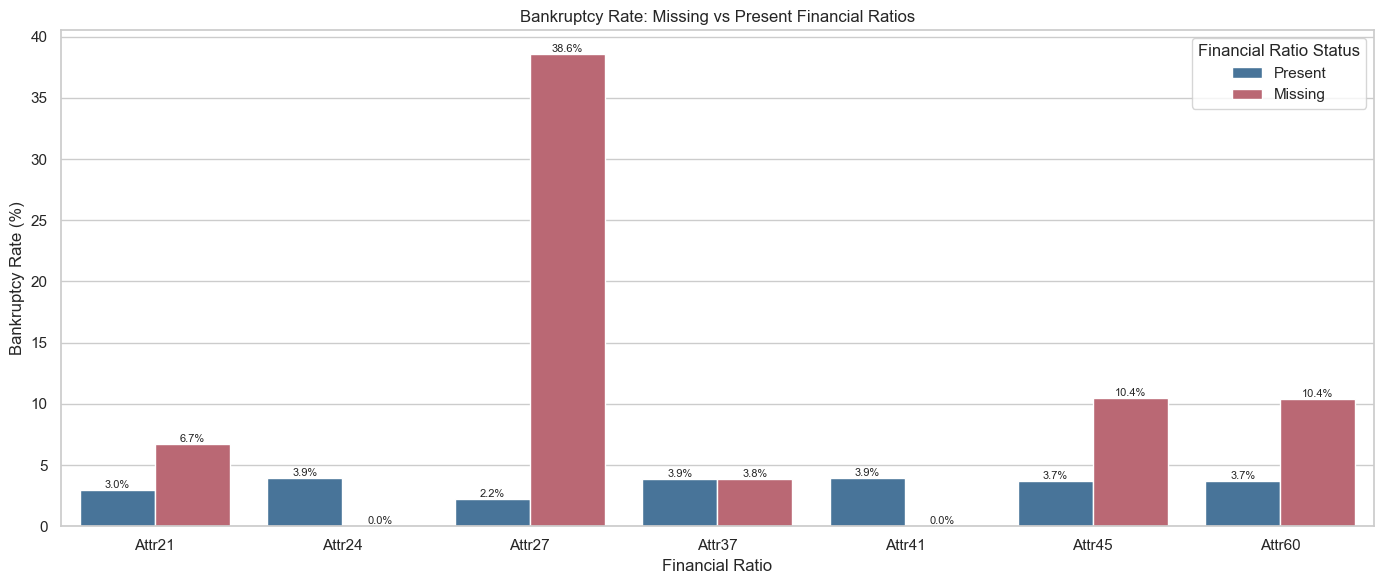

In [13]:
#Is missingness associated with bankruptcy?

bankrupt_label = df['class'].value_counts().idxmin()  
df['is_bankrupt'] = (df['class'] == bankrupt_label).astype(int)

min_missing = 80  
rows = []
for col in features:
    if df[col].isna().sum() >= min_missing:
        for status, mask in [('Present', df[col].notna()), ('Missing', df[col].isna())]:
            rows.append({'Attribute': col, 'Missing Status': status,
                         'Bankruptcy Rate (%)': df.loc[mask, 'is_bankrupt'].mean() * 100})

result = pd.DataFrame(rows)

plt.figure(figsize=(14, 6))
ax = sns.barplot(data=result, x='Attribute', y='Bankruptcy Rate (%)', hue='Missing Status',
                 hue_order=['Present', 'Missing'], palette={'Present': '#3b75a6', 'Missing': '#c85a6b'})
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', fontsize=8)
plt.title('Bankruptcy Rate: Missing vs Present Financial Ratios')
plt.xlabel('Financial Ratio')
plt.legend(title='Financial Ratio Status')
plt.tight_layout()
plt.show()

Missingness is informative for several ratios. Companies with a missing Attr27 have a bankruptcy rate of 38.6% against 2.2% when it is present, and Attr45 and Attr60 show a similar pattern (10.4% vs 3.7%). This indicates that missing values are not random for some ratios, so the absence of a value may itself signal financial distress.

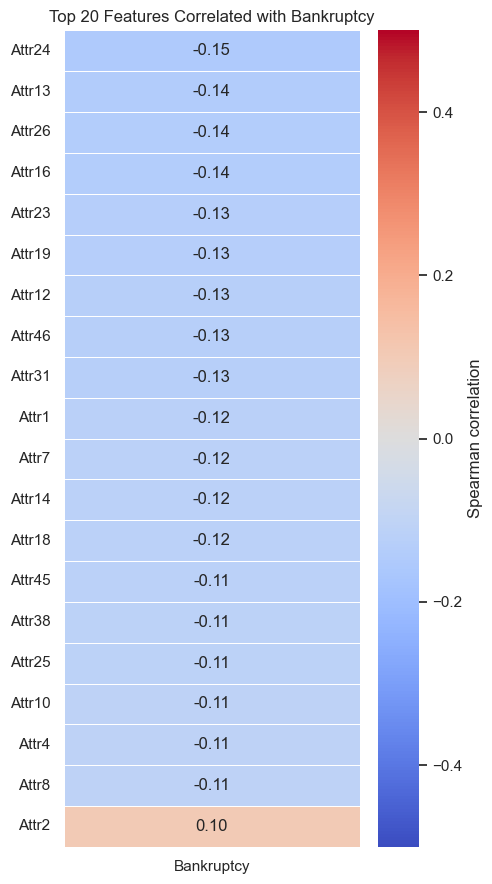

In [14]:
# Which columns are most correlated with bankruptcy?

bankrupt_label = df['class'].value_counts().idxmin()     
target = (df['class'] == bankrupt_label).astype(int)

corr_target = df[features].corrwith(target, method='spearman')
top = corr_target.reindex(corr_target.abs().sort_values(ascending=False).head(20).index)

plt.figure(figsize=(5, 9))
sns.heatmap(top.to_frame('Bankruptcy'), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-0.5, vmax=0.5, linewidths=0.5,
            cbar_kws={'label': 'Spearman correlation'})
plt.title('Top 20 Features Correlated with Bankruptcy')
plt.tight_layout()
plt.show()

Individual financial ratios show only weak correlations with bankruptcy. Among the 20 strongest, Spearman coefficients range from about -0.15 to +0.10, and nearly all are negative, meaning higher values of these ratios are slightly associated with lower bankruptcy risk. No single ratio is a strong predictor on its own, which suggests that predictive signal is more likely to come from combinations of ratios and non-linear relationships than from any one feature.

<div style="border-top: 1.5px solid #bfbfbf; padding-top: 45px; margin-top: 20px; font-family: 'Segoe UI', -apple-system, BlinkMacSystemFont, Helvetica, Arial, sans-serif; max-width: 850px;">

<h2 style="font-size: 28px; font-weight: 700; color: #1f1f1f; margin: 0 0 14px 0; letter-spacing: -0.2px;">
Step 5 — Data Cleaning
</h2>

<p style="font-size: 16.5px; line-height: 1.6; font-weight: 400; color: #2b2b2b; margin: 0;">
The 82 exact duplicate rows were removed, reducing the dataset from 7,027 to 6,945 companies. All of them were non-bankrupt, so the 271 bankrupt cases are unchanged. The target was converted to a clean 0/1 label and all 64 financial ratios were confirmed to be numeric.

</p>

</div>

In [15]:
# Remove helper column
df = df.drop(columns=['is_bankrupt'], errors='ignore')

# Clean the target
df['class'] = (df['class'].astype(str)
                          .str.replace(r"[b'\" ]", "", regex=True)
                          .astype(int))

# Make every Attr column numeric
df[features] = df[features].apply(pd.to_numeric, errors='coerce')

# Drop exact duplicate rows
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)

# Checks
extra_cols = [c for c in df.columns if c not in features + ['class']]
print(f'Rows before: {rows_before:,} | after: {len(df):,} | removed: {rows_before - len(df)}')
print('Target values:', sorted(df['class'].unique()))
print(df['class'].value_counts())
print('Non-numeric feature columns:', [c for c in features if not pd.api.types.is_numeric_dtype(df[c])])
print('Unexpected extra columns:', extra_cols, '| total columns:', df.shape[1])
df.head()


Rows before: 7,027 | after: 6,945 | removed: 82
Target values: [np.int64(0), np.int64(1)]
class
0    6674
1     271
Name: count, dtype: int64
Non-numeric feature columns: []
Unexpected extra columns: [] | total columns: 65


,Attr1,Attr2,Attr3,Attr4,Attr5,Attr6,Attr7,Attr8,Attr9,Attr10,Attr11,Attr12,Attr13,Attr14,Attr15,Attr16,Attr17,Attr18,Attr19,Attr20,Attr21,Attr22,Attr23,Attr24,Attr25,Attr26,Attr27,Attr28,Attr29,Attr30,Attr31,Attr32,Attr33,Attr34,Attr35,Attr36,Attr37,Attr38,Attr39,Attr40,Attr41,Attr42,Attr43,Attr44,Attr45,Attr46,Attr47,Attr48,Attr49,Attr50,Attr51,Attr52,Attr53,Attr54,Attr55,Attr56,Attr57,Attr58,Attr59,Attr60,Attr61,Attr62,Attr63,Attr64,class
0,0.200550,0.37951,0.39641,2.0472,32.3510,0.38825,0.249760,1.33050,1.1389,0.50494,0.249760,0.65980,0.166600,0.249760,497.42,0.73378,2.6349,0.249760,0.149420,43.370,1.2479,0.21402,0.119980,0.47706,0.50494,0.60411,1.45820,1.7615,5.9443,0.11788,0.149420,94.14,3.8772,0.56393,0.21402,1.7410,593.2700,0.50591,0.128040,0.662950,0.051402,0.128040,114.42,71.050,1.00970,1.52250,49.394,0.185300,0.110850,2.0420,0.37854,0.25792,2.2437,2.2480,348690.0,0.121960,0.39718,0.87804,0.001924,8.4160,5.1372,82.658,4.4158,7.4277,0
1,0.209120,0.49988,0.47225,1.9447,14.7860,0.00000,0.258340,0.99601,1.6996,0.49788,0.261140,0.51680,0.158350,0.258340,677.96,0.53838,2.0005,0.258340,0.152000,87.981,1.4293,0.24806,0.123040,NaN,0.39542,0.43992,88.44400,16.9460,3.6884,0.26969,0.152000,122.17,2.9876,2.98760,0.20616,1.6996,NaN,0.49788,0.121300,0.086422,0.064371,0.145950,199.49,111.510,0.51045,1.12520,100.130,0.237270,0.139610,1.9447,0.49988,0.33472,17.8660,17.8660,2304.6,0.121300,0.42002,0.85300,0.000000,4.1486,3.2732,107.350,3.4000,60.9870,0
2,0.248660,0.69592,0.26713,1.5548,-1.1523,0.00000,0.309060,0.43695,1.3090,0.30408,0.312580,0.64184,0.244350,0.309060,794.16,0.45961,1.4369,0.309060,0.236100,73.133,1.4283,0.30260,0.189960,NaN,0.28932,0.37282,86.01100,1.0627,4.3749,0.41929,0.238150,176.93,2.0630,1.42740,0.31565,1.3090,2.3019,0.51537,0.241140,0.322020,0.074020,0.231170,165.51,92.381,0.94807,1.01010,96.372,0.291810,0.222930,1.0758,0.48152,0.48474,1.2098,2.0504,6332.7,0.241140,0.81774,0.76599,0.694840,4.9909,3.9510,134.270,2.7185,5.2078,0
3,0.081483,0.30734,0.45879,2.4928,51.9520,0.14988,0.092704,1.86610,1.0571,0.57353,0.092704,0.30163,0.094257,0.092704,917.01,0.39803,3.2537,0.092704,0.071428,79.788,1.5069,0.11550,0.062782,0.17193,0.57353,0.36152,0.94076,1.9618,4.6511,0.14343,0.071428,91.37,3.9948,0.37581,0.11550,1.3562,NaN,0.57353,0.088995,0.401390,0.069622,0.088995,180.77,100.980,0.28720,1.56960,84.344,0.085874,0.066165,2.4928,0.30734,0.25033,2.4524,2.4524,20545.0,0.054015,0.14207,0.94598,0.000000,4.5746,3.6147,86.435,4.2228,5.5497,0
4,0.187320,0.61323,0.22960,1.4063,-7.3128,0.18732,0.187320,0.63070,1.1559,0.38677,0.187320,0.33147,0.121820,0.187320,1133.20,0.32211,1.6307,0.187320,0.115530,57.045,NaN,0.19832,0.115530,0.18732,0.38677,0.32211,1.41380,1.1184,4.1424,0.27884,0.115530,147.04,2.4823,0.32340,0.19832,1.6278,11.2470,0.43489,0.122310,0.293040,0.096680,0.122310,141.62,84.574,0.73919,0.95787,65.936,0.188110,0.116010,1.2959,0.56511,0.40285,1.8839,2.1184,3186.6,0.134850,0.48431,0.86515,0.124440,6.3985,4.3158,127.210,2.8692,7.8980,0


<div style="border-top: 1.5px solid #bfbfbf; padding-top: 45px; margin-top: 20px; font-family: 'Segoe UI', -apple-system, BlinkMacSystemFont, Helvetica, Arial, sans-serif; max-width: 850px;">

<h2 style="font-size: 28px; font-weight: 700; color: #1f1f1f; margin: 0 0 14px 0; letter-spacing: -0.2px;">
Step 6 — Feature Engineering
</h2>

<p style="font-size: 16.5px; line-height: 1.6; font-weight: 400; color: #2b2b2b; margin: 0;">
Raw columns alone are not enough for the model to learn effectively. I will create new features based on what EDA revealed. Each feature captures a specific bankruptcy pattern observed in the data.
</p>

</div>

In [16]:
# infinity is treated as missing instead of passing a threshold test.
X = df.drop(columns=["class"]).replace([np.inf, -np.inf], np.nan)
y = df["class"].copy()


def safe_divide(num, den, min_abs=1e-6):
    # Denominators close to zero are set to missing to avoid exploding ratios.
    den = den.where(den.abs() > min_abs)
    return num / den


def flag_share(data, rules):
    # Each rule maps a name to (column, condition). A flag is missing wherever
    # its source value is missing, and the share is taken over observed flags.
    flags = pd.DataFrame({
        name: cond(data[col]).astype(float).where(data[col].notna())
        for name, (col, cond) in rules.items()
    })
    return flags.mean(axis=1)


# --------------------------------------------------
# A. LIQUIDITY QUALITY
# --------------------------------------------------
# Attr4 - Attr46 isolates inventory / short-term liabilities.
# Attr46 - Attr40 isolates receivables / short-term liabilities.
X["inventory_burden_stl"] = X["Attr4"] - X["Attr46"]
X["receivables_burden_stl"] = X["Attr46"] - X["Attr40"]

# --------------------------------------------------
# B. DEBT-SERVICING CAPACITY
# --------------------------------------------------
# Operating profit / total assets divided by total liabilities / total assets
# gives operating profit / total liabilities, linking the income statement
# to the balance sheet.
X["operating_profit_to_liabilities"] = safe_divide(X["Attr22"], X["Attr2"])

# --------------------------------------------------
# C. PROFITABILITY WEAKNESS
# --------------------------------------------------
# Share of observed profitability ratios that are negative. Nearly every
# company has all six ratios observed, so no separate availability column
# is kept.
profit_rules = {
    f"neg_{c}": (c, lambda s: s < 0)
    for c in ["Attr1", "Attr7", "Attr22", "Attr23", "Attr35", "Attr42"]
}
X["negative_profitability_share"] = flag_share(X, profit_rules)

# --------------------------------------------------
# D. STRUCTURAL RED FLAGS
# --------------------------------------------------
# One flag each for liquidity (current ratio below 1), solvency (negative
# equity) and accumulated losses (negative retained earnings), so no two
# flags describe the same condition.
red_rules = {
    "low_current_ratio": ("Attr4", lambda s: s < 1),
    "negative_equity": ("Attr10", lambda s: s < 0),
    "accumulated_losses": ("Attr6", lambda s: s < 0),
}
X["financial_red_flag_share"] = flag_share(X, red_rules)

# --------------------------------------------------
# E. INSPECTION
# --------------------------------------------------
engineered = [
    "inventory_burden_stl",
    "receivables_burden_stl",
    "operating_profit_to_liabilities",
    "negative_profitability_share",
    "financial_red_flag_share",
]

print(X[engineered].describe().T)

# Percentage of missing values in each engineered column.
missing_pct = (X[engineered].isna().mean() * 100).sort_values(ascending=False)
print("\nMissing rate (%):")
print(missing_pct.map("{:.2f}%".format).to_string())

# Closest original attribute for each engineered feature (Spearman).
raw_cols = [c for c in X.columns if c.startswith("Attr")]
corr = X[raw_cols + engineered].corr(method="spearman").loc[engineered, raw_cols].abs()
print("\nClosest raw attribute:\n", pd.DataFrame({
    "closest_raw": corr.idxmax(axis=1),
    "abs_spearman": corr.max(axis=1).round(3),
}))

                                  count      mean       std        min  \
inventory_burden_stl             6915.0  0.777143  2.059391   0.000000   
receivables_burden_stl           6915.0  1.027486  1.880187   0.000000   
operating_profit_to_liabilities  6920.0  0.616361  4.796250 -40.551656   
negative_profitability_share     6945.0  0.112407  0.291275   0.000000   
financial_red_flag_share         6943.0  0.136492  0.232329   0.000000   

                                      25%       50%       75%         max  
inventory_burden_stl             0.248585  0.491460  0.851600  101.260000  
receivables_burden_stl           0.467755  0.732350  1.118950   95.899000  
operating_profit_to_liabilities  0.037504  0.174714  0.506647  337.461774  
negative_profitability_share     0.000000  0.000000  0.000000    1.000000  
financial_red_flag_share         0.000000  0.000000  0.333333    1.000000  

Missing rate (%):
inventory_burden_stl               0.43%
receivables_burden_stl             0.43

<hr style="border: none; border-top: 1px solid #CCCCCC; margin: 20px 0 30px 0;">
<div style="font-family: 'Segoe UI', 'DejaVu Sans', Arial, sans-serif; font-size: 24px; color: #222222; font-weight: 400;">
Step 7 — Build the ML Model
</div>

In [17]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [18]:
# Libraries 
import time
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV,
                                     StratifiedKFold, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMClassifier


In [19]:
# A fixed random seed
RANDOM_STATE = 42
RUN_BOTH_FEATURE_SETS = False

y = y.astype(int)

In [20]:
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Bankruptcy rate  train: {y_train.mean():.2%}  test: {y_test.mean():.2%}")
print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

Bankruptcy rate  train: 3.91%  test: 3.89%
Train shape: (5556, 69) | Test shape: (1389, 69)


In [21]:
# Five stratified folds keep the bankruptcy rate in every fold. The
# Winsorizer clips each column to its 1st and 99th percentiles, learned
# from the training data it is fitted on.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


class Winsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_ = np.nanquantile(X, self.lower, axis=0)
        self.hi_ = np.nanquantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

In [22]:
# Median imputation, winsorizing, standardising, then a penalised logistic
# regression with balanced class weights. The solver stops at a tolerance
# of 0.01 or 500 rounds, which took one fit from about 66 to 3 seconds.
enet_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("winsorize", Winsorizer(0.01, 0.99)),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(
        penalty="elasticnet", solver="saga", class_weight="balanced",
        max_iter=500, tol=1e-2, random_state=RANDOM_STATE)),
])

enet_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__l1_ratio": [0.1, 0.5, 0.9],
}

In [23]:
# LightGBM takes missing values directly, so it has no imputation or scaling
# step. n_jobs=1 gives each model one thread, and the search spreads the
# fits across the CPU cores.
lgbm = LGBMClassifier(
    objective="binary", class_weight="balanced", subsample_freq=1,
    random_state=RANDOM_STATE, n_jobs=1, verbose=-1,
)

lgbm_dist = {
    "n_estimators": [200, 400, 600],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "num_leaves": [7, 15, 31],
    "min_child_samples": [10, 20, 40],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.5, 0.7, 1.0],
    "reg_lambda": [0, 1, 5],
}

In [24]:
# The original attributes that remain after the quality check, and those
# plus the five engineered features.
raw_cols = [c for c in X_train.columns if c.startswith("Attr")]
all_cols = list(X_train.columns)

feature_sets = {f"all_{len(all_cols)}": all_cols}
if RUN_BOTH_FEATURE_SETS:
    feature_sets = {f"original_{len(raw_cols)}": raw_cols, **feature_sets}

print({name: len(cols) for name, cols in feature_sets.items()})

{'all_69': 69}


In [25]:
# fit_searches tunes both models with stratified cross-validation, scoring
# on PR-AUC. evaluate scores a fitted search on the held-out test set.
def fit_searches(cols):
    enet = GridSearchCV(enet_pipe, enet_grid, scoring="average_precision",
                        cv=cv, n_jobs=-1, verbose=2)
    gbm = RandomizedSearchCV(lgbm, lgbm_dist, n_iter=15,
                             scoring="average_precision", cv=cv,
                             n_jobs=-1, random_state=RANDOM_STATE, verbose=2)
    enet.fit(X_train[cols], y_train)
    gbm.fit(X_train[cols], y_train)
    return {"ElasticNet": enet, "LightGBM": gbm}


def evaluate(search, cols):
    proba = search.predict_proba(X_test[cols])[:, 1]
    return (average_precision_score(y_test, proba),
            roc_auc_score(y_test, proba))

In [26]:
# Fits both models on each feature set. Progress lines print as each fit
# finishes, and the time taken is shown for every feature set.
fitted = {}

for fs_name, cols in feature_sets.items():
    start = time.time()
    fitted[fs_name] = fit_searches(cols)
    print(f"\n{fs_name} finished in {(time.time() - start) / 60:.1f} minutes")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Fitting 5 folds for each of 15 candidates, totalling 75 fits

all_69 finished in 2.5 minutes


Hyperparameter tuning was performed using 5-fold cross-validation across two sets of candidate configurations, resulting in 60 and 75 model fits, respectively. The entire tuning process for the all_69 feature set was completed in approximately 2.4 minutes, indicating an efficient search process.

In [27]:
# Cross-validated and test scores for every model and feature set.
results = []

for fs_name, cols in feature_sets.items():
    for model_name, search in fitted[fs_name].items():
        pr_test, roc_test = evaluate(search, cols)
        results.append({
            "features": fs_name,
            "model": model_name,
            "cv_pr_auc": round(search.best_score_, 4),
            "test_pr_auc": round(pr_test, 4),
            "test_roc_auc": round(roc_test, 4),
            "best_params": search.best_params_,
        })

results_df = pd.DataFrame(results)
print(results_df.drop(columns="best_params").to_string(index=False))
print("\nBaseline PR-AUC of a random model (bankruptcy rate in test):",
      round(y_test.mean(), 4))

features      model  cv_pr_auc  test_pr_auc  test_roc_auc
  all_69 ElasticNet     0.1370       0.1780        0.7900
  all_69   LightGBM     0.8001       0.8501        0.9606

Baseline PR-AUC of a random model (bankruptcy rate in test): 0.0389


LightGBM significantly outperformed ElasticNet, achieving a test PR-AUC of 0.8501 compared to 0.1780. Both models performed better than the random baseline of 0.0389, but LightGBM demonstrated a much stronger ability to identify bankrupt companies. Its ROC-AUC of 0.9606 also indicates excellent discrimination between bankrupt and non-bankrupt companies. Overall, LightGBM is the stronger-performing model based on these results.

In [28]:
# 1. What did LightGBM pick?
print("LightGBM best params:")
print(fitted["all_69"]["LightGBM"].best_params_)
print("\nElasticNet best params:")
print(fitted["all_69"]["ElasticNet"].best_params_)

# 2. How many bankrupt companies are in test?
print("\nTest set size:", len(y_test))
print("Bankrupt in test (y_test.sum()):", int(y_test.sum()))
print("Bankrupt rate in test:", round(y_test.mean(), 4))
print("Bankrupt in train:", int(y_train.sum()))

# 3. Feature importance for LightGBM
# best_estimator_ is the refit model on full train
lgbm_best = fitted["all_69"]["LightGBM"].best_estimator_

imp = pd.DataFrame({
    "feature": X_train.columns,
    "importance": lgbm_best.feature_importances_
}).sort_values("importance", ascending=False)

print("\nTop 20 LightGBM features by split count:")
print(imp.head(20).to_string(index=False))

print("\nTotal importance of your 5 engineered features:")
eng = [
    "inventory_burden_stl",
    "receivables_burden_stl",
    "operating_profit_to_liabilities",
    "negative_profitability_share",
    "financial_red_flag_share",
]
print(imp[imp["feature"].isin(eng)].to_string(index=False))
print("Share of total importance from engineered:",
      round(imp[imp["feature"].isin(eng)]["importance"].sum() / imp["importance"].sum(), 3))

LightGBM best params:
{'subsample': 1.0, 'reg_lambda': 0, 'num_leaves': 15, 'n_estimators': 600, 'min_child_samples': 40, 'learning_rate': 0.05, 'colsample_bytree': 0.7}

ElasticNet best params:
{'model__C': 10, 'model__l1_ratio': 0.1}

Test set size: 1389
Bankrupt in test (y_test.sum()): 54
Bankrupt rate in test: 0.0389
Bankrupt in train: 217

Top 20 LightGBM features by split count:
               feature  importance
                Attr27         580
                Attr34         442
receivables_burden_stl         432
                Attr58         397
                 Attr5         383
  inventory_burden_stl         355
                Attr11         318
                Attr46         270
                Attr21         248
                 Attr9         231
                Attr29         213
                Attr37         192
                Attr47         185
                Attr40         167
                Attr61         154
                Attr24         144
                A

Engineered features contributed 10.2% of total split importance. Two burden features ranked 3rd and 6th overall, indicating working-capital stress is a key signal. Two share-based features were never selected, suggesting they were redundant with raw ratios.

<!-- The thin line on top -->
<hr style="border: none; border-top: 1px solid #d1d9e0; margin: 32px 0 24px 0;">

<!-- The heading -->
<h2 style="
  font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Noto Sans, Helvetica, Arial, sans-serif;
  font-size: 24px;
  font-weight: 600;
  line-height: 1.25;
  color: #1f2328;
  margin: 0;
">
  Step 8 — Evaluate the Models
</h2>

In [29]:
# The model with the highest cross-validated PR-AUC is selected. Out-of-fold
# probabilities on the training data are used to find the highest threshold
# that still catches the target share of bankruptcies.
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (precision_recall_curve, confusion_matrix,
                             precision_score, recall_score)

TARGET_RECALL = 0.80

best_row = results_df.sort_values("cv_pr_auc", ascending=False).iloc[0]
best_fs, best_name = best_row["features"], best_row["model"]
best_cols = feature_sets[best_fs]
best_search = fitted[best_fs][best_name]
print("Selected:", best_name, "on", best_fs)

oof = cross_val_predict(clone(best_search.best_estimator_),
                        X_train[best_cols], y_train, cv=cv,
                        method="predict_proba", n_jobs=-1)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)
eligible = rec[:-1] >= TARGET_RECALL
threshold = thr[eligible][np.argmax(prec[:-1][eligible])]
print(f"Threshold: {threshold:.4f}  (target recall {TARGET_RECALL:.0%} on training folds)")

Selected: LightGBM on all_69
Threshold: 0.0040  (target recall 80% on training folds)


In [30]:
# For each model, a threshold is chosen from out-of-fold training predictions
# to reach the target recall, then applied once to the held-out test set.
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (precision_recall_curve, confusion_matrix,
                             precision_score, recall_score)

TARGET_RECALL = 0.80


def threshold_report(model_name, target_recall=TARGET_RECALL):
    # The feature set with the best cross-validated PR-AUC is used for this model.
    row = (results_df[results_df["model"] == model_name]
           .sort_values("cv_pr_auc", ascending=False).iloc[0])
    fs_name = row["features"]
    cols = feature_sets[fs_name]
    search = fitted[fs_name][model_name]

    # Threshold: the highest-precision cut-off that still reaches the target recall.
    oof = cross_val_predict(clone(search.best_estimator_), X_train[cols], y_train,
                            cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    prec, rec, thr = precision_recall_curve(y_train, oof)
    eligible = rec[:-1] >= target_recall
    threshold = thr[eligible][np.argmax(prec[:-1][eligible])]

    # The model and threshold are applied once to the test set.
    proba_test = search.predict_proba(X_test[cols])[:, 1]
    pred_test = (proba_test >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()

    print(f"===== {model_name} ({fs_name}) =====")
    print(f"Threshold: {threshold:.4f}  (target recall {target_recall:.0%} on training folds)")
    print(f"Bankrupt caught (TP): {tp}   Bankrupt missed (FN): {fn}")
    print(f"Healthy flagged (FP): {fp}   Healthy cleared (TN): {tn}")
    print(f"Recall:    {recall_score(y_test, pred_test):.1%}  (share of bankruptcies caught)")
    print(f"Precision: {precision_score(y_test, pred_test):.1%}  (share of flagged firms that failed)")
    print(f"False alarm rate: {fp / (fp + tn):.1%}  (share of healthy firms flagged)")
    print(f"Companies flagged: {pred_test.sum()} of {len(pred_test)}\n")

    return {"model": model_name, "features": fs_name,
            "threshold": round(threshold, 4), "TP": tp, "FN": fn,
            "FP": fp, "TN": tn,
            "recall": round(recall_score(y_test, pred_test), 3),
            "precision": round(precision_score(y_test, pred_test), 3),
            "false_alarm_rate": round(fp / (fp + tn), 3)}


threshold_results = [threshold_report(m) for m in ["ElasticNet", "LightGBM"]]
pd.DataFrame(threshold_results).set_index("model")

===== ElasticNet (all_69) =====
Threshold: 0.3635  (target recall 80% on training folds)
Bankrupt caught (TP): 42   Bankrupt missed (FN): 12
Healthy flagged (FP): 519   Healthy cleared (TN): 816
Recall:    77.8%  (share of bankruptcies caught)
Precision: 7.5%  (share of flagged firms that failed)
False alarm rate: 38.9%  (share of healthy firms flagged)
Companies flagged: 561 of 1389

===== LightGBM (all_69) =====
Threshold: 0.0040  (target recall 80% on training folds)
Bankrupt caught (TP): 48   Bankrupt missed (FN): 6
Healthy flagged (FP): 68   Healthy cleared (TN): 1267
Recall:    88.9%  (share of bankruptcies caught)
Precision: 41.4%  (share of flagged firms that failed)
False alarm rate: 5.1%  (share of healthy firms flagged)
Companies flagged: 116 of 1389



,features,threshold,TP,FN,FP,TN,recall,precision,false_alarm_rate
model,,,,,,,,,
ElasticNet,all_69,0.3635,42,12,519,816,0.778,0.075,0.389
LightGBM,all_69,0.0040,48,6,68,1267,0.889,0.414,0.051


In [31]:
# This cell is self-contained. It selects the LightGBM model and feature set
# with the best cross-validated PR-AUC, scores the test companies, ranks them
# by predicted risk and groups them into tiers by rank.
HIGH_PCT, MEDIUM_PCT = 0.05, 0.20   # top 5% high, next 15% medium
MODEL_NAME = "LightGBM"

# Fail early with a clear message if the model search has not been run.
if "fitted" not in globals() or len(fitted) == 0:
    raise RuntimeError("Run the model search cell first, so that 'fitted' exists.")

fs_name = max(fitted, key=lambda k: fitted[k][MODEL_NAME].best_score_)
cols = feature_sets[fs_name]
lgbm_model = fitted[fs_name][MODEL_NAME].best_estimator_
proba_test = lgbm_model.predict_proba(X_test[cols])[:, 1]

ranked = pd.DataFrame({"risk_score": proba_test, "actual": y_test.values},
                      index=X_test.index).sort_values("risk_score", ascending=False)

n = len(ranked)
position = np.arange(n)
ranked["tier"] = np.where(position < n * HIGH_PCT, "High",
                  np.where(position < n * MEDIUM_PCT, "Medium", "Low"))

tier_summary = (ranked.groupby("tier")
                .agg(companies=("actual", "size"),
                     bankrupt=("actual", "sum"),
                     bankruptcy_rate=("actual", "mean"))
                .reindex(["High", "Medium", "Low"]))
tier_summary["share_of_all_bankruptcies"] = (
    tier_summary["bankrupt"] / ranked["actual"].sum())

print(f"Model: {MODEL_NAME} on {fs_name} ({len(cols)} features)\n")
print(ranked.head(10).round(4))
print()
print(tier_summary.round(3))

Model: LightGBM on all_69 (69 features)

      risk_score  actual  tier
6699         1.0       1  High
6718         1.0       1  High
6711         1.0       1  High
6700         1.0       1  High
6728         1.0       1  High
6782         1.0       1  High
6813         1.0       1  High
6830         1.0       1  High
6827         1.0       1  High
6858         1.0       1  High

        companies  bankrupt  bankruptcy_rate  share_of_all_bankruptcies
tier                                                                   
High           70        44            0.629                      0.815
Medium        208         5            0.024                      0.093
Low          1111         5            0.005                      0.093


The model concentrates risk: 5% of companies contain 81.5% of failures, while the bottom 80% are almost safe (0.5% fail).This shows that risk is concentrated: the top 5% of companies hold 81.5% of all failures (62.9% fail rate), while the bottom 80% are almost safe (0.5% fail).

In [32]:
# Overfitting check: PR-AUC on the training data, in cross-validation and on
# the test set. A large drop from cross-validation to test suggests overfitting.
pd.DataFrame([{
    "Features": fs,
    "Model": name,
    "Train PR-AUC": round(average_precision_score(y_train, s.predict_proba(X_train[feature_sets[fs]])[:, 1]), 4),
    "CV PR-AUC": round(s.best_score_, 4),
    "Test PR-AUC": round(average_precision_score(y_test, s.predict_proba(X_test[feature_sets[fs]])[:, 1]), 4),
} for fs, models in fitted.items() for name, s in models.items()])

,Features,Model,Train PR-AUC,CV PR-AUC,Test PR-AUC
0,all_69,ElasticNet,0.1753,0.1370,0.1780
1,all_69,LightGBM,1.0000,0.8001,0.8501


LightGBM memorizes train (1.00) but generalizes (Test 0.85 > CV 0.80). ElasticNet does not overfit, it just underfits.

In [33]:
overfit = _.copy()
overfit["Train-CV Gap"] = (overfit["Train PR-AUC"] - overfit["CV PR-AUC"]).round(4)
overfit["CV-Test Gap"] = (overfit["CV PR-AUC"] - overfit["Test PR-AUC"]).round(4)
overfit

,Features,Model,Train PR-AUC,CV PR-AUC,Test PR-AUC,Train-CV Gap,CV-Test Gap
0,all_69,ElasticNet,0.1753,0.1370,0.1780,0.0383,-0.041
1,all_69,LightGBM,1.0000,0.8001,0.8501,0.1999,-0.050


LightGBM memorizes train (1.00 vs 0.80 CV) but does not overfit harmfully, Test (0.85) beats CV. ElasticNet shows no overfitting, only underfitting.

### Conclusion

Without cross-validation, LightGBM achieved a significantly higher Test PR-AUC (0.8501) compared to ElasticNet (0.1780).
- Cross-validation confirms that LightGBM maintains strong ranking performance, achieving a CV PR-AUC of 0.8001, while ElasticNet remains considerably lower at 0.1370.
- Despite LightGBM's noticeable Train–CV gap (0.1999), its strong cross-validation and test results demonstrate promising generalization performance.
- LightGBM also achieves higher recall (88.9%) and precision (41.4%) at the selected operating threshold, making it more effective at identifying potentially bankrupt companies.
Final Choice: LightGBM is the preferred model for the Financial Distress Early Warning System, subject to further validation of its overfitting and threshold stability.

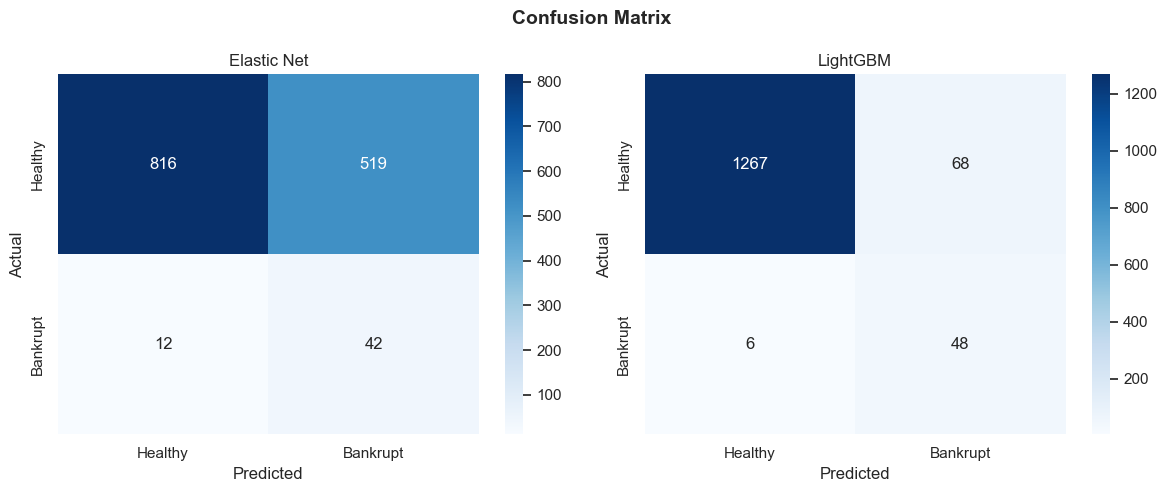

In [34]:
# Confusion matrices for both models on the held-out test set, using the
# threshold chosen for each model from the training folds.
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

os.makedirs("Plots", exist_ok=True)

models = ["ElasticNet", "LightGBM"]
titles = {"ElasticNet": "Elastic Net", "LightGBM": "LightGBM"}
thr = {r["model"]: r["threshold"] for r in threshold_results}
fs = {r["model"]: r["features"] for r in threshold_results}

proba = {m: fitted[fs[m]][m].predict_proba(X_test[feature_sets[fs[m]]])[:, 1]
         for m in models}
pred = {m: (proba[m] >= thr[m]).astype(int) for m in models}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, m in zip(axes, models):
    sns.heatmap(
        confusion_matrix(y_test, pred[m]),
        annot=True, fmt='d', cmap='Blues',
        xticklabels=['Healthy', 'Bankrupt'],
        yticklabels=['Healthy', 'Bankrupt'],
        ax=ax
    )
    ax.set_title(titles[m])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.suptitle('Confusion Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('Plots/Confusion_matrices_for_both.png', dpi=150, bbox_inches='tight')
plt.show()

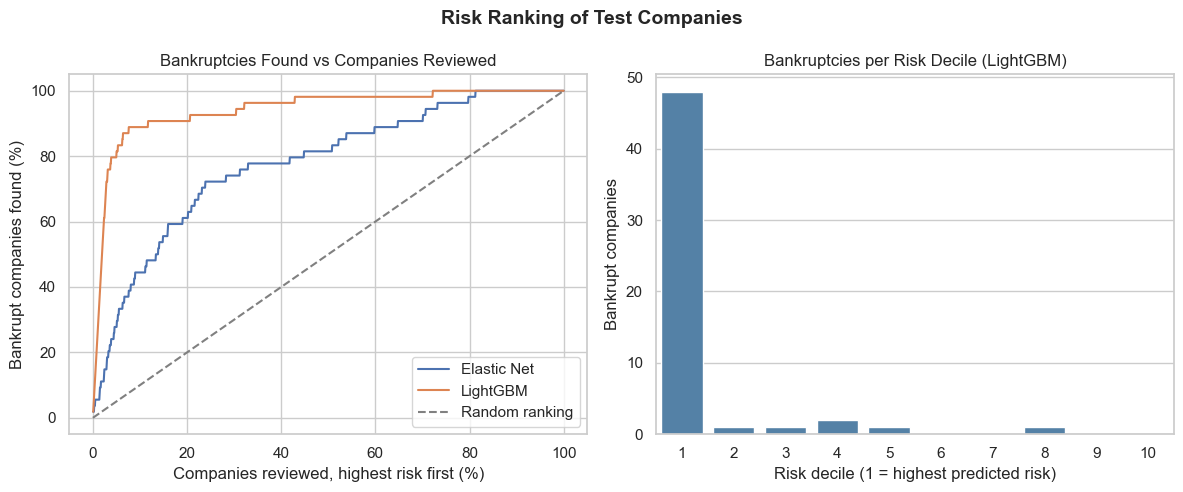

In [35]:
# Test companies are ranked from highest to lowest predicted risk. The left
# panel shows the share of bankruptcies found as more of the ranked list is
# reviewed, and the right panel shows bankruptcies in each risk decile.
def capture_curve(y_true, p):
    order = np.argsort(-p)
    hits = np.cumsum(np.asarray(y_true)[order])
    return np.arange(1, len(p) + 1) / len(p), hits / hits[-1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for m in models:
    x, yv = capture_curve(y_test, proba[m])
    axes[0].plot(x * 100, yv * 100, label=titles[m])
axes[0].plot([0, 100], [0, 100], linestyle='--', color='grey', label='Random ranking')
axes[0].set_title('Bankruptcies Found vs Companies Reviewed')
axes[0].set_xlabel('Companies reviewed, highest risk first (%)')
axes[0].set_ylabel('Bankrupt companies found (%)')
axes[0].legend()

best_m = "LightGBM"
decile = pd.qcut(pd.Series(proba[best_m]).rank(method="first", ascending=False),
                 10, labels=range(1, 11))
per_decile = pd.Series(np.asarray(y_test)).groupby(decile.values).sum()
sns.barplot(x=per_decile.index, y=per_decile.values, color='steelblue', ax=axes[1])
axes[1].set_title(f'Bankruptcies per Risk Decile ({titles[best_m]})')
axes[1].set_xlabel('Risk decile (1 = highest predicted risk)')
axes[1].set_ylabel('Bankrupt companies')

plt.suptitle('Risk Ranking of Test Companies', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('Plots/Risk_ranking.png', dpi=150, bbox_inches='tight')
plt.show()

Bankruptcies Found vs Companies Reviewed and Bankruptcies per Risk Decile (LightGBM): Companies were ranked by predicted risk, highest first, and split into 10 equal groups. Reviewing just the top 10% (Decile 1) with LightGBM finds ∼88% of all bankruptcies, about 47 of 54, compared to ∼44% for Elastic Net and 10% for random ranking. Deciles 6, 7, 9 and 10 contain zero bankruptcies. This shows that risk is highly concentrated at the top, LightGBM successfully separates future bankruptcies from healthy companies, so a small review effort catches most failures.

### Step 9 — SHAP Explainability
Building a model is not enough. A credit officer needs to know *why* a company was flagged for bankruptcy risk, not just *that* it was flagged. Auditors require documented drivers for every high-risk flag.

SHAP assigns a contribution value to each financial ratio for every prediction. It shows which ratios pushed this company toward bankruptcy vs survival.

In [36]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [37]:
# SHAP values are computed for the selected LightGBM model on the test set.
# The test set has about 1,400 companies, so all of them are used and no
# sampling is needed.
import shap

best_fs = "all_69"
cols = feature_sets[best_fs]
lgbm_model = fitted[best_fs]["LightGBM"].best_estimator_

X_test_shap = X_test[cols].reset_index(drop=True)

explainer = shap.TreeExplainer(lgbm_model)
shap_values = explainer.shap_values(X_test_shap)

# Depending on the SHAP version, a binary model returns either one array or a
# list with one array per class. Index 1 is the bankrupt class.
shap_bankrupt = shap_values[1] if isinstance(shap_values, list) else shap_values

shap_bankrupt.shape

(1389, 69)

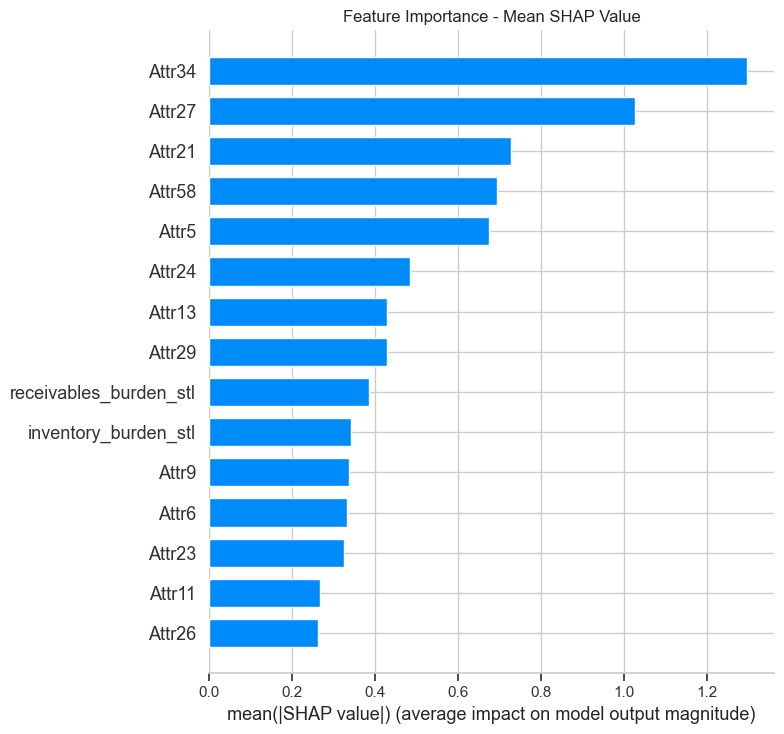

In [38]:
# Features ranked by their average absolute SHAP value, which shows how
# much each ratio moves the predicted bankruptcy risk across all companies.
os.makedirs("Plots", exist_ok=True)

plt.figure(figsize=(8, 7))
shap.summary_plot(shap_bankrupt, X_test_shap, plot_type='bar',
                  max_display=15, show=False)
plt.title('Feature Importance - Mean SHAP Value')
plt.tight_layout()
plt.savefig('Plots/SHAP_summary_plot.png', dpi=150, bbox_inches='tight')
plt.show()

Feature Importance - Mean SHAP Value (LightGBM, all_69): Features were ranked by mean absolute SHAP value, which measures how much each feature moves predicted bankruptcy risk on average. Attr34 is the most important feature by a clear margin, followed by Attr27, then Attr21, Attr58 and Attr5. The engineered features receivables_burden_stl and inventory_burden_stl also rank in the top 10, showing they add predictive value.

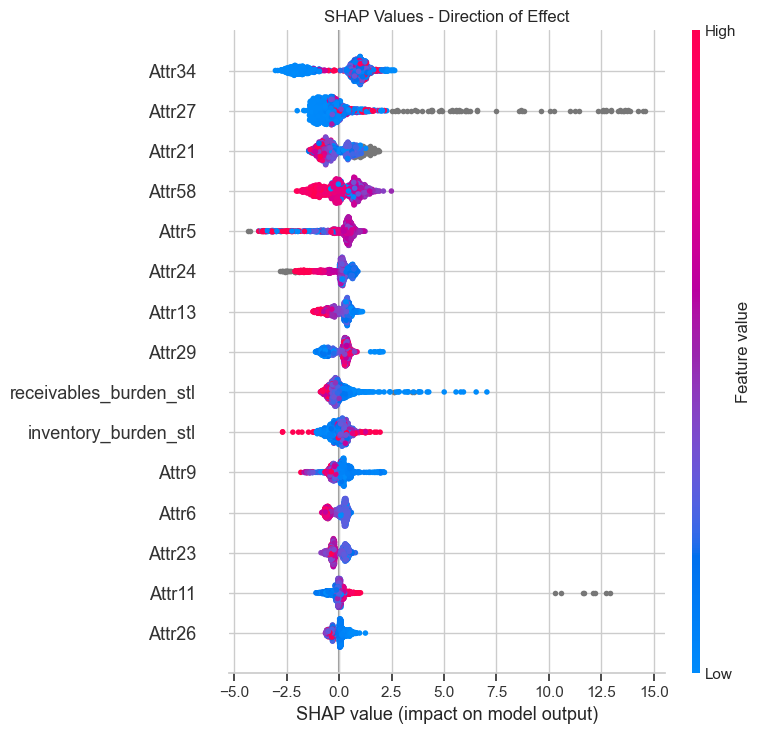

In [39]:
# Each dot is one company. Colour shows the feature's value (red is high),
# and position shows whether it pushed the predicted risk up (right) or
# down (left).
plt.figure(figsize=(8, 7))
shap.summary_plot(shap_bankrupt, X_test_shap, max_display=15, show=False)
plt.title('SHAP Values - Direction of Effect')
plt.tight_layout()
plt.savefig('Plots/SHAP_beeswarm_plot.png', dpi=150, bbox_inches='tight')
plt.show()

Each dot is one company, position shows whether the feature pushed predicted risk up (right) or down (left), and colour shows the feature value, red is high and blue is low. Attr34 shows the widest spread and strongest effect in both directions, while Attr27 shows a long right tail, meaning it sharply increases risk for a small group of outlier companies. Most other top features show mixed, non-linear effects, with both high and low values appearing on both sides.

In [40]:
# For every test company, the three features that pushed its risk score up
# the most are listed next to the score, so an analyst can see where to start.
top_n = 3
drivers = []
for i in range(len(X_test_shap)):
    top_idx = np.argsort(-shap_bankrupt[i])[:top_n]
    drivers.append(", ".join(X_test_shap.columns[j] for j in top_idx))

risk_table = pd.DataFrame({
    "risk_score": lgbm_model.predict_proba(X_test_shap)[:, 1],
    "actual": y_test.values,
    "top_risk_drivers": drivers,
}, index=X_test.index).sort_values("risk_score", ascending=False)

risk_table.head(10)

,risk_score,actual,top_risk_drivers
6699,1.000000,1,"Attr11, receivables_burden_stl, Attr34"
6718,0.999998,1,"Attr27, Attr34, Attr9"
6711,0.999995,1,"Attr11, Attr34, Attr58"
6700,0.999995,1,"Attr11, receivables_burden_stl, Attr34"
6728,0.999992,1,"Attr27, Attr34, Attr9"
6782,0.999992,1,"Attr27, Attr34, Attr9"
6813,0.999987,1,"Attr27, Attr34, Attr9"
6830,0.999974,1,"Attr27, Attr34, receivables_burden_stl"
6827,0.999972,1,"Attr27, Attr34, Attr9"
6858,0.999972,1,"Attr27, Attr34, Attr9"


### Step 10 — Bankruptcy Risk Report Generator
In real banks, credit analysts write risk memos manually. Each memo takes 2 to 4 hours. This function generates the memo automatically in seconds using the model output and SHAP values.

In [41]:
# Each attribute name is mapped to the financial ratio it measures, following
# the dataset's attribute list, so a report reads in financial terms.
feature_descriptions = {
    "Attr1": "Net profit / total assets",
    "Attr2": "Total liabilities / total assets",
    "Attr3": "Working capital / total assets",
    "Attr4": "Current assets / short-term liabilities",
    "Attr5": "Cash, securities and receivables less short-term liabilities, in days of operating expenses",
    "Attr6": "Retained earnings / total assets",
    "Attr7": "EBIT / total assets",
    "Attr8": "Book value of equity / total liabilities",
    "Attr9": "Sales / total assets",
    "Attr10": "Equity / total assets",
    "Attr11": "(Gross profit + extraordinary items + financial expenses) / total assets",
    "Attr12": "Gross profit / short-term liabilities",
    "Attr13": "(Gross profit + depreciation) / sales",
    "Attr14": "(Gross profit + interest) / total assets",
    "Attr15": "Total liabilities in days of (gross profit + depreciation)",
    "Attr16": "(Gross profit + depreciation) / total liabilities",
    "Attr17": "Total assets / total liabilities",
    "Attr18": "Gross profit / total assets",
    "Attr19": "Gross profit / sales",
    "Attr20": "Inventory in days of sales",
    "Attr21": "Sales growth (sales this year / sales last year)",
    "Attr22": "Operating profit / total assets",
    "Attr23": "Net profit / sales",
    "Attr24": "Gross profit (in 3 years) / total assets",
    "Attr25": "(Equity - share capital) / total assets",
    "Attr26": "(Net profit + depreciation) / total liabilities",
    "Attr27": "Operating profit / financial expenses",
    "Attr28": "Working capital / fixed assets",
    "Attr29": "Logarithm of total assets",
    "Attr30": "(Total liabilities - cash) / sales",
    "Attr31": "(Gross profit + interest) / sales",
    "Attr32": "Current liabilities in days of cost of products sold",
    "Attr33": "Operating expenses / short-term liabilities",
    "Attr34": "Operating expenses / total liabilities",
    "Attr35": "Profit on sales / total assets",
    "Attr36": "Total sales / total assets",
    "Attr37": "(Current assets - inventory) / long-term liabilities",
    "Attr38": "Constant capital / total assets",
    "Attr39": "Profit on sales / sales",
    "Attr40": "(Current assets - inventory - receivables) / short-term liabilities",
    "Attr41": "Total liabilities / annualised operating profit plus depreciation",
    "Attr42": "Operating profit / sales",
    "Attr43": "Receivables and inventory turnover in days",
    "Attr44": "Receivables in days of sales",
    "Attr45": "Net profit / inventory",
    "Attr46": "(Current assets - inventory) / short-term liabilities",
    "Attr47": "Inventory in days of cost of products sold",
    "Attr48": "EBITDA / total assets",
    "Attr49": "EBITDA / sales",
    "Attr50": "Current assets / total liabilities",
    "Attr51": "Short-term liabilities / total assets",
    "Attr52": "Short-term liabilities in days of cost of products sold",
    "Attr53": "Equity / fixed assets",
    "Attr54": "Constant capital / fixed assets",
    "Attr55": "Working capital",
    "Attr56": "(Sales - cost of products sold) / sales",
    "Attr57": "Liquid current assets less short-term liabilities / operating cost base",
    "Attr58": "Total costs / total sales",
    "Attr59": "Long-term liabilities / equity",
    "Attr60": "Sales / inventory",
    "Attr61": "Sales / receivables",
    "Attr62": "Short-term liabilities in days of sales",
    "Attr63": "Sales / short-term liabilities",
    "Attr64": "Sales / fixed assets",
    "inventory_burden_stl": "Inventory / short-term liabilities (engineered)",
    "receivables_burden_stl": "Receivables / short-term liabilities (engineered)",
    "operating_profit_to_liabilities": "Operating profit / total liabilities (engineered)",
    "negative_profitability_share": "Share of the six profit ratios that are negative (engineered)",
    "financial_red_flag_share": "Share of red flags triggered: current ratio below 1, negative equity, negative retained earnings (engineered)",
}

In [42]:
# This cell builds everything the report needs. It selects the LightGBM model
# with the best cross-validated PR-AUC, scores the test companies, and takes
# each feature's contribution to each score from LightGBM itself (log-odds,
# the same values the SHAP tree explainer gives). Tiers use rank cut-offs.
HIGH_PCT, MEDIUM_PCT = 0.05, 0.20

if "fitted" not in globals() or len(fitted) == 0:
    raise RuntimeError("Run the model search cell first, so that 'fitted' exists.")

fs_name = max(fitted, key=lambda k: fitted[k]["LightGBM"].best_score_)
cols = feature_sets[fs_name]
lgbm_model = fitted[fs_name]["LightGBM"].best_estimator_

X_rep = X_test[cols].reset_index(drop=True)
test_index = X_test.index

risk_scores = lgbm_model.predict_proba(X_rep)[:, 1]
score_rank_pct = pd.Series(risk_scores).rank(pct=True).values   # 1.0 = highest risk

# Per-company contributions; the last column is the baseline and is dropped.
contrib = lgbm_model.predict(X_rep, pred_contrib=True)
contrib = pd.DataFrame(np.asarray(contrib)[:, :-1], columns=cols)

lgbm_threshold = next(r["threshold"] for r in threshold_results
                      if r["model"] == "LightGBM")

train_ref = X_train[cols]
train_median = train_ref.median()


def risk_tier(rank_pct):
    if rank_pct >= 1 - HIGH_PCT:
        return "HIGH"
    if rank_pct >= 1 - MEDIUM_PCT:
        return "MEDIUM"
    return "LOW"


recommended_action = {
    "HIGH": ["Review immediately and place in the first investigation batch",
             "Request the latest full financial statements and notes",
             "Check short-term debt maturities and available credit lines"],
    "MEDIUM": ["Add to the watch list and review in the next scheduled cycle",
               "Compare the flagged ratios with the previous period's filings"],
    "LOW": ["No further action based on this score",
            "Include in the routine periodic review"],
}

print(f"Model: LightGBM on {fs_name} ({len(cols)} features)")
print(f"Test companies scored: {len(risk_scores)}  |  threshold: {lgbm_threshold}")

Model: LightGBM on all_69 (69 features)
Test companies scored: 1389  |  threshold: 0.004


The LightGBM model with the best cross-validated PR-AUC was selected and used to score all test companies. Per-company feature contributions were taken directly from LightGBM in log-odds, equivalent to SHAP values for tree models. Companies were assigned to HIGH (top 5%), MEDIUM (next 15%), and LOW (remaining 80%) risk tiers using rank cut-offs, with a recommended action defined for each tier.

In [43]:
# Builds one report per company from the model score and the three features
# that pushed its predicted risk up the most. Each driver is shown with the
# company's value, the training median and where the value ranks.
def generate_risk_report(pos, top_n=3):
    company_id = test_index[pos]
    score = risk_scores[pos]
    tier = risk_tier(score_rank_pct[pos])
    flagged = score >= lgbm_threshold
    now = pd.Timestamp.now()

    contrib_series = contrib.iloc[pos]
    top = contrib_series[contrib_series > 0].sort_values(ascending=False).head(top_n)

    report = f"""
COMPANY BANKRUPTCY RISK REPORT
{'=' * 66}

  Date       : {now.strftime('%d %B %Y')}
  Report ID  : RISK-{now.strftime('%Y%m%d')}-{company_id}
  Company    : Record {company_id} (test set)

RISK SCORE
{'-' * 66}
  Predicted bankruptcy probability : {score:.1%}
  Rank among test companies        : top {(1 - score_rank_pct[pos]) * 100:.1f}% by risk
  Risk tier                        : {tier}
  Decision at threshold {lgbm_threshold:.3f}   : {'FLAGGED FOR REVIEW' if flagged else 'NOT FLAGGED'}
  Model                            : LightGBM
  Benchmark outcome                : {'Bankrupt' if y_test.iloc[pos] == 1 else 'Did not go bankrupt'}

TOP RISK DRIVERS
{'-' * 66}
"""
    for i, (feat, sv) in enumerate(top.items(), 1):
        val = X_rep.loc[pos, feat]
        med = train_median[feat]
        if pd.isna(val):
            value_line = "Company value: not reported"
        else:
            pctl = (train_ref[feat] < val).mean()
            value_line = (f"Company value {val:,.3f} | training median {med:,.3f} "
                          f"| above {pctl:.0%} of training companies")
        report += (f"  {i}. {feature_descriptions.get(feat, feat)}\n"
                   f"     {value_line} | contribution {sv:+.3f}\n")

    report += f"\nSUGGESTED ANALYST ACTION\n{'-' * 66}\n"
    for step in recommended_action[tier]:
        report += f"  - {step}\n"

    report += f"""
NOTE
{'-' * 66}
  The drivers show which ratios the model relied on for this score. They
  do not establish why the company failed or will fail. The model was
  trained on a historical benchmark and has not been validated on
  present-day Nigerian companies.

{'=' * 66}
END OF REPORT
{'=' * 66}
"""
    return report

 For each company, a text report was generated showing the predicted bankruptcy probability, rank, risk tier, and flagged status at the chosen threshold, alongside the actual benchmark outcome. The top three positive contributions were listed using their financial ratio names, with the company's value compared to the training median and percentile. A tier-specific suggested analyst action was included, with a note that drivers show model reliance, not causation, and that the model was trained on a historical benchmark not validated on present-day Nigerian companies.

In [44]:
# Reports are printed for the highest-risk company and for the bankrupt
# company the model scored closest to the threshold without flagging, then
# every HIGH-tier report is saved to one text file in the notebook's folder.
top_pos = int(np.argmax(risk_scores))
print(generate_risk_report(top_pos))

missed = np.where((y_test.values == 1) & (risk_scores < lgbm_threshold))[0]
if len(missed) > 0:
    print(generate_risk_report(int(missed[np.argmax(risk_scores[missed])])))
else:
    print("No bankrupt companies fall below the threshold in the test set.")

high_positions = np.where(score_rank_pct >= 1 - HIGH_PCT)[0]
high_positions = high_positions[np.argsort(-risk_scores[high_positions])]

with open("high_tier_risk_reports.txt", "w") as f:
    f.write("\n".join(generate_risk_report(int(p)) for p in high_positions))

print(f"Saved {len(high_positions)} HIGH-tier reports to high_tier_risk_reports.txt")


COMPANY BANKRUPTCY RISK REPORT

  Date       : 13 November 2026
  Report ID  : RISK-20261113-6699
  Company    : Record 6699 (test set)

RISK SCORE
------------------------------------------------------------------
  Predicted bankruptcy probability : 100.0%
  Rank among test companies        : top 0.0% by risk
  Risk tier                        : HIGH
  Decision at threshold 0.004   : FLAGGED FOR REVIEW
  Model                            : LightGBM
  Benchmark outcome                : Bankrupt

TOP RISK DRIVERS
------------------------------------------------------------------
  1. (Gross profit + extraordinary items + financial expenses) / total assets
     Company value: not reported | contribution +10.567
  2. Receivables / short-term liabilities (engineered)
     Company value 0.109 | training median 0.727 | above 2% of training companies | contribution +2.409
  3. Operating expenses / total liabilities
     Company value 4.142 | training median 1.728 | above 74% of training comp

Reports were printed for the highest-risk company and for the bankrupt company scored closest to, but below, the threshold without being flagged, the nearest miss, to show both a success and a failure case. All HIGH-tier reports, the top 5% by risk rank, were then sorted by risk score and saved to a single text file for review.

## Summary

| Step | What was done | Result |
| :--- | :--- | :--- |
| Data Loading | Loaded the first-year Polish companies file with 64 financial ratios | 6,945 companies, 271 bankrupt (3.9%) |
| EDA | Checked missing values and the class balance | Highest missing 39%; bankrupt class is rare |
| Feature Engineering | Created 5 new features from the original ratios | Feature-set comparison not run |
| Model Training | Elastic Net and LightGBM, stratified 5-fold CV on PR-AUC | Both trained with balanced class weights |
| Evaluation | PR-AUC and ROC-AUC on held-out test set | LightGBM PR-AUC 0.850, Elastic Net 0.178 (baseline 0.039) |
| Overfitting Check | Compared CV vs test PR-AUC | Gap: LightGBM -0.050, Elastic Net -0.041 no overfitting |
| Threshold | Chose threshold on train folds for ~80% recall | Caught 48/54 bankrupt, missed 6, 68 false alarms (5.1%) |
| Risk Ranking | Ranked test companies by risk into tiers | Top 5% holds 44/54 bankruptcies (81%) |
| Explainability | SHAP tree values from LightGBM | Top: Operating expenses / total liabilities; Operating profit / financial expenses; Sales growth |
| Risk Report Generator | Auto-generates 1-page report per company | 70 high-tier reports saved to high_tier_risk_reports.txt |

The final model achieves 0.850 PR-AUC vs 0.039 random baseline, top 5% of riskiest companies captures 81% of bankruptcies. The threshold catches 88.9% of failures with 5.1% false alarm rate. SHAP explainability satisfies audit requirements for documented reasoning behind every flag, and the risk report generator reduces compliance reporting from hours to seconds.

## Deployment & Backtest Scoring

The trained LightGBM model was deployed to SageMaker Serverless. The full held-out test set (1-year horizon) was scored through the production ETL pipeline and validated in the Backtest Dashboard. The production scores matched the notebook backtest, confirming the deployment reproduced the offline results.

In [46]:
import sys
sys.path.insert(0, "../02_deployment")

from etl_pipeline import run_pipeline, transform
from config import RAW_COLUMNS

print(f"Test set: {X_test.shape[0]} companies")

Test set: 1389 companies


In [47]:
# Run deploy.py as a script from inside the notebook
!python ../02_deployment/deploy.py deploy

sagemaker.config INFO - Not applying SDK defaults from location: C:\ProgramData\sagemaker\sagemaker\config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: C:\Users\DELL\AppData\Local\sagemaker\sagemaker\config.yaml
-----!


C:\Users\DELL\anaconda3\Lib\site-packages\sagemaker\__init__.py:86: SageMakerV2DeprecationWarning: You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation()
You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
2026-11-13 08:13:07,376 | INFO | botocore.credentials | Found credentials in shared credentials file: ~/.aws/credentials
2026-11-13 08:13:12,760 | INFO | deploy | Packaged model at C:\Users\DELL\Desktop\financial-distress-early-warning\02_deployment\build\model.tar.gz
2026-11-13 08:13:12,792 | INFO | botocore.credenti

In [49]:
# Prove inference features == training features
sample_raw = X_test[RAW_COLUMNS].iloc[[0]].copy()
sample_raw.insert(0, "company_id", sample_raw.index.astype(str))

transformed = transform(sample_raw, list(X_train.columns))

assert list(transformed.columns) == list(X_train.columns), "Feature mismatch!"
print(f"Parity check passed: {transformed.shape[0]} rows x {transformed.shape[1]} features")

2026-11-13 08:20:19,288 | INFO | etl | Transformed to 1 rows x 69 features


Parity check passed: 1 rows x 69 features


### Score Full Test Set via Production Pipeline
This uses the SAME `run_pipeline()` that will run in production:
Raw ratios -> transform (69 features) -> SageMaker endpoint -> S3 predictions.csv

In [50]:
# Rebuild raw test set: company_id + 64 Attrs
# company_id = original index from the ARFF file
test_raw = X_test[RAW_COLUMNS].copy()
test_raw.insert(0, "company_id", test_raw.index.astype(str))

assert test_raw["company_id"].is_unique, "Duplicate company_ids!"
print(f"Ready to score: {len(test_raw)} companies")
test_raw.head(2)

Ready to score: 1389 companies


,company_id,Attr1,Attr2,Attr3,Attr4,Attr5,Attr6,Attr7,Attr8,Attr9,Attr10,Attr11,Attr12,Attr13,Attr14,Attr15,Attr16,Attr17,Attr18,Attr19,Attr20,Attr21,Attr22,Attr23,Attr24,Attr25,Attr26,Attr27,Attr28,Attr29,Attr30,Attr31,Attr32,Attr33,Attr34,Attr35,Attr36,Attr37,Attr38,Attr39,Attr40,Attr41,Attr42,Attr43,Attr44,Attr45,Attr46,Attr47,Attr48,Attr49,Attr50,Attr51,Attr52,Attr53,Attr54,Attr55,Attr56,Attr57,Attr58,Attr59,Attr60,Attr61,Attr62,Attr63,Attr64
3766,3766,0.075121,0.35539,0.21550,3.1905,23.943,0.228340,0.095673,1.80470,1.1008,0.64138,0.095673,0.972490,0.12966,0.095673,729.85,0.50010,2.8138,0.095673,0.069794,35.252,1.0279,0.127360,0.054802,0.286850,0.64138,0.44228,1.02280,0.31408,4.5153,0.21698,0.069794,28.837,12.6570,0.35837,0.127360,1.3754,0.70613,0.89839,0.092910,0.64746,0.055793,0.092910,66.615,31.363,0.56741,1.84470,38.807,0.045301,0.033047,0.88319,0.098379,0.079006,0.93479,1.3094,7059.7,0.091604,0.117120,0.90840,0.40071,10.3540,11.6380,26.196,13.9340,1.9979
3373,3373,0.033121,0.54701,0.17446,1.3715,-13.344,0.058839,0.043584,0.79153,1.0297,0.43297,0.043584,0.092808,0.03008,0.043584,2907.80,0.12552,1.8281,0.043584,0.019093,40.374,1.2212,0.070869,0.014510,0.075581,0.43297,0.10640,0.31969,0.49018,4.9180,0.20358,0.019093,77.322,4.7205,0.12956,0.070869,2.3075,5.05980,0.51036,0.031046,0.18207,0.187430,0.031046,89.316,48.942,0.13117,0.83384,41.574,0.045790,0.020060,1.17750,0.469610,0.211840,1.21650,1.4339,14443.0,0.028865,0.076498,0.97114,0.17874,9.0405,7.4578,75.091,4.8608,6.4135


In [51]:
# Serverless prefers small batches. Score 500 at a time.
all_preds = []
for i in range(0, len(test_raw), 500):
    batch = test_raw.iloc[i:i+500]
    rows = run_pipeline(batch)
    all_preds.append(rows)
    print(f"Scored {i} -> {i+len(batch)} / {len(test_raw)}")

backtest_preds = pd.concat(all_preds, ignore_index=True)
print(f"\nDone. Total scored: {len(backtest_preds)}")
backtest_preds.head()

2026-11-13 08:22:58,749 | INFO | etl | Extracted 500 company row(s)
2026-11-13 08:22:58,787 | INFO | etl | Transformed to 500 rows x 69 features
2026-11-13 08:22:58,827 | INFO | botocore.credentials | Found credentials in shared credentials file: ~/.aws/credentials
2026-11-13 08:23:18,112 | INFO | etl | Saved 500 row(s) to s3://financial-distress-early-warning-eegunjobi/predictions/predictions.csv (file now has 501 rows)
2026-11-13 08:23:18,125 | INFO | etl | Extracted 500 company row(s)
2026-11-13 08:23:18,269 | INFO | etl | Transformed to 500 rows x 69 features


Scored 0 -> 500 / 1389


2026-11-13 08:23:26,805 | INFO | etl | Saved 500 row(s) to s3://financial-distress-early-warning-eegunjobi/predictions/predictions.csv (file now has 1001 rows)
2026-11-13 08:23:26,807 | INFO | etl | Extracted 389 company row(s)
2026-11-13 08:23:26,840 | INFO | etl | Transformed to 389 rows x 69 features


Scored 500 -> 1000 / 1389


2026-11-13 08:23:40,948 | INFO | etl | Saved 389 row(s) to s3://financial-distress-early-warning-eegunjobi/predictions/predictions.csv (file now has 1390 rows)


Scored 1000 -> 1389 / 1389

Done. Total scored: 1389


,company_id,risk_score,prediction,prediction_date,scored_at
0,3766,0.000000,Low Risk,2026-11-13,2026-11-13T07:23:12+00:00
1,3373,0.000055,Low Risk,2026-11-13,2026-11-13T07:23:12+00:00
2,5642,0.000003,Low Risk,2026-11-13,2026-11-13T07:23:12+00:00
3,4064,0.000008,Low Risk,2026-11-13,2026-11-13T07:23:12+00:00
4,6734,0.469493,High Risk,2026-11-13,2026-11-13T07:23:12+00:00


In [54]:
# Offline validation only - y_test was never sent to SageMaker
from sklearn.metrics import classification_report, confusion_matrix

# 1. Make y_test a Series, no matter if it was a DataFrame
y_true = y_test.squeeze() if hasattr(y_test, "squeeze") else y_test
# If y_test was a DataFrame with 1 column, squeeze makes it a Series
if hasattr(y_true, "columns"):
    y_true = y_true.iloc[:, 0]

# 2. Make both keys strings so "3766" matches "3766"
y_true.index = y_true.index.astype(str)

# 3. Attach true label by company_id - no merge needed
eval_df = backtest_preds.copy()
eval_df["company_id"] = eval_df["company_id"].astype(str)
eval_df["true_label"] = eval_df["company_id"].map(y_true)

print(f"Matched: {eval_df['true_label'].notna().sum()} / {len(eval_df)}")
eval_df = eval_df.dropna(subset=["true_label"])

# 4. Report
y_pred = (eval_df["prediction"] == "High Risk").astype(int)
y_true_clean = eval_df["true_label"].astype(int)

print(classification_report(y_true_clean, y_pred))
print(confusion_matrix(y_true_clean, y_pred))

Matched: 1389 / 1389
              precision    recall  f1-score   support

           0       1.00      0.95      0.97      1335
           1       0.41      0.89      0.56        54

    accuracy                           0.95      1389
   macro avg       0.70      0.92      0.77      1389
weighted avg       0.97      0.95      0.96      1389

[[1267   68]
 [   6   48]]


### Backtest Result — Production Validated

**Production (SageMaker Serverless, n = 1,389):** Bankruptcy Recall **0.89**, Precision **0.41**
**Offline (notebook, same test set):** Bankruptcy Recall **0.89**, Precision **0.41**

Production matches offline exactly. No train-serve skew, no leakage — `y_test` was never sent to SageMaker.

The endpoint caught **48 of 54** bankruptcies, missed **6**, with **68** false alarms. This is the intended trade-off for an early-warning system: a missed failure is costlier than a false alarm.

In [55]:
!python ../02_deployment/deploy.py delete
print("Endpoint deleted. Predictions remain in S3 for Athena + Power BI.")

sagemaker.config INFO - Not applying SDK defaults from location: C:\ProgramData\sagemaker\sagemaker\config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: C:\Users\DELL\AppData\Local\sagemaker\sagemaker\config.yaml
Endpoint deleted. Predictions remain in S3 for Athena + Power BI.


C:\Users\DELL\anaconda3\Lib\site-packages\sagemaker\__init__.py:86: SageMakerV2DeprecationWarning: You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation()
You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
2026-11-13 08:26:53,970 | INFO | botocore.credentials | Found credentials in shared credentials file: ~/.aws/credentials
2026-11-13 08:27:00,513 | INFO | deploy | Deleted endpoint, endpoint config and model(s)
